# Exercice 3 — Mini-BERT, en bonus

On entraîne depuis zéro un encodeur qui retrouve des mots masqués.
Ce n'est pas le BERT préentraîné du second notebook : le corpus est petit,
le vocabulaire est construit sur nos phrases, et les poids partent au hasard.

Les identifiants réservés sont `PAD=0`, `UNK=1`, `CLS=2`, `SEP=3`, `MASK=4`.
Chaque phrase est complétée jusqu'à 32 tokens :

`[CLS] le chat dort sur le canapé [SEP] [PAD] ...`

On sélectionne environ 15 % des tokens ordinaires. Parmi eux, 80 % deviennent
`[MASK]`, 10 % un mot ordinaire aléatoire, et 10 % restent visibles. La perte
ne concerne que ces positions, grâce à `ignore_index=-100`.
        

In [1]:
import sys
from pathlib import Path

%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists() and (ROOT.parent / "src").exists():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from src.training import count_parameters, get_device, set_seed

set_seed(42)
device = get_device()
print("Dossier du projet :", ROOT)
print("Périphérique :", device)

Dossier du projet : /Users/hmid/Downloads/Deep-Learning-Transformers
Périphérique : mps


## 1. Phrases et vocabulaire

Les phrases de validation réutilisent uniquement des mots vus à l'entraînement,
mais ce ne sont pas les mêmes combinaisons. Le modèle peut donc être interrogé
sur des phrases connues pour la démonstration, et mesuré sur des phrases tenues
à l'écart pour l'exactitude.

Le réseau feed-forward interne fait `64 → 256 → 64`. Le sujet ne fixe pas cette
largeur : 256 reprend le même facteur quatre que le mini-GPT. Le dropout vaut 0,1.
L'attention n'a pas de masque causal. Elle a un masque de padding.
        

In [2]:
from src.data import (
    build_minibert_corpus,
    build_word_vocab,
    encode_sentences,
    tokenize_words,
)

phrases_train, phrases_val = build_minibert_corpus()
stoi, itos = build_word_vocab(phrases_train)
ids_train = encode_sentences(phrases_train, stoi, max_length=32)
ids_val = encode_sentences(phrases_val, stoi, max_length=32)
print("Phrases train / validation :", len(phrases_train), len(phrases_val))
print("Vocabulaire :", len(stoi))
print("Forme :", tuple(ids_train.shape), tuple(ids_val.shape))
exemple = encode_sentences(["le chat dort sur le canapé"], stoi)[0]
print("Exemple :", " ".join(itos[int(i)] for i in exemple if int(i) != stoi["[PAD]"]))
        

Phrases train / validation : 576 48
Vocabulaire : 92
Forme : (576, 32) (48, 32)
Exemple : [CLS] le chat dort sur le canapé [SEP]


In [3]:
from src.text_models import corrupt_for_mlm

generateur = torch.Generator().manual_seed(42)
corrompu, labels, selection = corrupt_for_mlm(ids_train[:4], len(stoi), generateur)
for ligne in range(4):
    mots = [itos[int(indice)] for indice in corrompu[ligne] if int(indice) != 0]
    cibles = [
        itos[int(labels[ligne, colonne])]
        for colonne in range(labels.size(1))
        if int(labels[ligne, colonne]) != -100
    ]
    print("entrée :", " ".join(mots))
    print("à prédire :", cibles)
    print()
        

entrée : [CLS] un élève comprend le [MASK] [SEP]
à prédire : ['masque']

entrée : [CLS] le [MASK] lit la séquence [SEP]
à prédire : ['réseau']

entrée : [CLS] la famille [MASK] la lampe [SEP]
à prédire : ['allume']

entrée : [CLS] le réfrigérateur [MASK] pendant la nuit [SEP]
à prédire : ['fonctionne']



## 2. Entraînement

Adam, pas de 0,001, 30 époques, lots de 32. Ce budget est un choix de travail :
le sujet demande un entraînement, pas un nombre d'époques. On conserve l'époque
de meilleure perte de validation. L'exactitude affichée pendant l'entraînement
dépend des masques tirés à cette époque. La mesure finale est refaite ensuite,
avec une graine fixe, sur le modèle retenu.
        

In [4]:
from src.text_models import MiniBERT
from src.training import evaluate_masked_language_model, train_masked_language_model

set_seed(42)
mini_bert = MiniBERT(vocab_size=len(stoi), max_length=32, dropout=0.1)
print("Paramètres :", count_parameters(mini_bert))
historique = train_masked_language_model(
    mini_bert,
    ids_train,
    ids_val,
    vocab_size=len(stoi),
    epochs=30,
    batch_size=32,
    lr=1e-3,
    device=device,
    seed=42,
)
final = evaluate_masked_language_model(
    mini_bert, ids_val, vocab_size=len(stoi), device=device, seed=123
)
print(f"Exactitude de validation, masques figés par la graine 123 : {final['accuracy']:.2%}")
print(f"Perte de validation correspondante : {final['loss']:.4f}")
        

Paramètres : 113884


Epoch   1 | train 4.0574 | val 3.7654 | exactitude val 17.86%  <- meilleur
Epoch   2 | train 3.4243 | val 3.1275 | exactitude val 30.16%  <- meilleur


Epoch   3 | train 3.0615 | val 2.9468 | exactitude val 31.15%  <- meilleur
Epoch   4 | train 2.6776 | val 2.6746 | exactitude val 27.87%  <- meilleur


Epoch   5 | train 2.4321 | val 2.3881 | exactitude val 40.68%  <- meilleur
Epoch   6 | train 2.2200 | val 2.3941 | exactitude val 37.70%


Epoch   7 | train 1.8823 | val 1.9719 | exactitude val 42.37%  <- meilleur
Epoch   8 | train 1.7387 | val 1.9518 | exactitude val 50.00%  <- meilleur


Epoch   9 | train 1.5251 | val 1.9240 | exactitude val 48.39%  <- meilleur
Epoch  10 | train 1.3386 | val 1.9692 | exactitude val 45.31%


... (7 outputs left out)

Epoch  25 | train 0.2984 | val 1.6395 | exactitude val 50.94%
Epoch  26 | train 0.2927 | val 1.8775 | exactitude val 50.00%


Epoch  27 | train 0.3021 | val 1.9219 | exactitude val 42.31%
Epoch  28 | train 0.2667 | val 1.7035 | exactitude val 53.45%


Epoch  29 | train 0.3286 | val 2.0274 | exactitude val 49.23%
Epoch  30 | train 0.2711 | val 1.8995 | exactitude val 57.38%
Meilleur mini-BERT restauré, perte de validation 1.1175


Exactitude de validation, masques figés par la graine 123 : 49.18%
Perte de validation correspondante : 1.5247


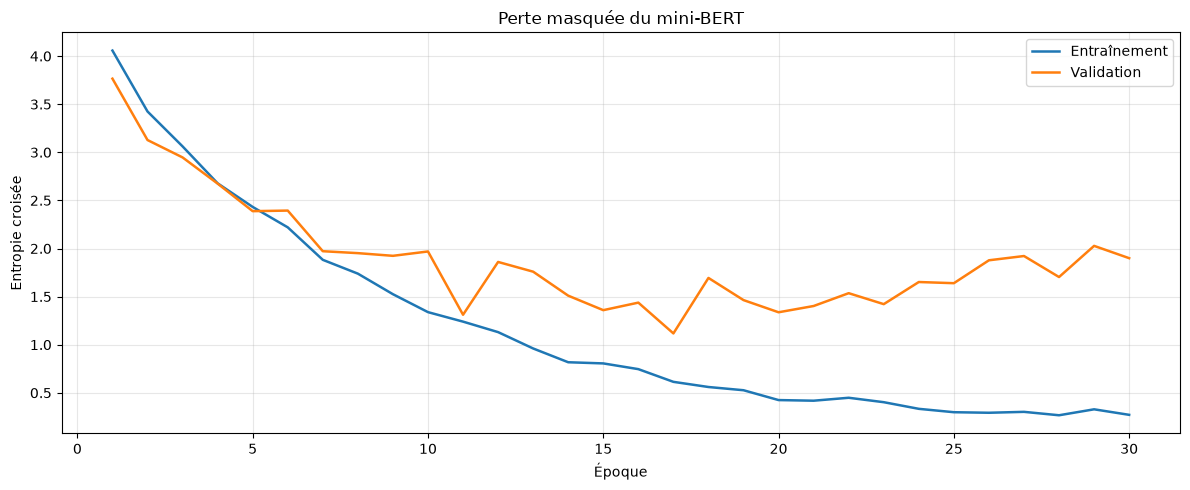

paris est la capitale de la france -> masque sur capitale
  1. capitale              64.7%  <-- mot d'origine
  2. ville                 13.4%
  3. paris                  3.0%
le chat dort sur le canapé -> masque sur dort
  1. dort                  58.1%  <-- mot d'origine
  2. reste                 31.8%
  3. regarde                0.8%
le chien dort sur le tapis -> masque sur tapis
  1. tapis                 79.7%  <-- mot d'origine
  2. canapé                 5.5%
  3. salon                  3.1%
la consommation augmente le soir -> masque sur augmente
  1. augmente              57.5%  <-- mot d'origine
  2. utilise                6.5%
  3. éclaire                4.1%


In [5]:
from src.evaluation import plot_loss_curves, save_figure, save_json
from src.text_models import topk_words

figure = plot_loss_curves(
    {
        "Entraînement": [ligne["train_loss"] for ligne in historique],
        "Validation": [ligne["val_loss"] for ligne in historique],
    },
    "Perte masquée du mini-BERT",
    ylabel="Entropie croisée",
)
save_figure(figure, ROOT / "outputs" / "figures" / "05_minibert_pertes.png")
plt.show()

def montrer(phrase: str, mot: str) -> None:
    mots = tokenize_words(phrase)
    position = 1 + mots.index(mot)
    ids = encode_sentences([phrase], stoi)[0].clone()
    vrai = itos[int(ids[position])]
    ids[position] = stoi["[MASK]"]
    masque = ids.eq(stoi["[PAD]"]).unsqueeze(0)
    mini_bert.eval()
    with torch.no_grad():
        logits = mini_bert(ids.unsqueeze(0).to(device), masque.to(device)).cpu()[0]
    propositions = topk_words(logits, position, itos, k=3)
    print(phrase, "-> masque sur", mot)
    for rang, (token, proba) in enumerate(propositions, start=1):
        marque = "  <-- mot d'origine" if token == vrai else ""
        print(f"  {rang}. {token:20s} {proba:6.1%}{marque}")

montrer("paris est la capitale de la france", "capitale")
montrer("le chat dort sur le canapé", "dort")
montrer("le chien dort sur le tapis", "tapis")
montrer("la consommation augmente le soir", "augmente")
        

## 3. Invariance au padding

On change les identifiants placés sur les positions de padding, sans changer
le masque. En mode `eval()`, les logits des tokens utiles doivent rester les mêmes.
        

In [6]:
ids = encode_sentences(["le chat dort sur le canapé"], stoi)
masque_pad = ids.eq(stoi["[PAD]"])
autre = ids.clone()
autre[masque_pad] = torch.arange(5, 5 + int(masque_pad.sum()))
mini_bert.eval()
with torch.no_grad():
    logits_a = mini_bert(ids.to(device), masque_pad.to(device)).cpu()
    logits_b = mini_bert(autre.to(device), masque_pad.to(device)).cpu()
utiles = ~masque_pad
ecart = (logits_a[utiles] - logits_b[utiles]).abs().max().item()
print(f"Écart maximal hors padding : {ecart:.3e}")
if ecart > 1e-4:
    raise RuntimeError("Le masque de padding ne bloque pas les jetons de remplissage.")
print("Les prédictions utiles sont inchangées.")

save_json(ROOT / "outputs" / "metrics" / "05_minibert.json", {
    "device": str(device),
    "vocabulaire": len(stoi),
    "exactitude_validation": final["accuracy"],
    "perte_validation": final["loss"],
    "positions_evaluees": final["selected"],
    "ecart_padding": ecart,
    "historique_final": historique[-1],
})
        

Écart maximal hors padding : 0.000e+00
Les prédictions utiles sont inchangées.


PosixPath('/Users/hmid/Downloads/Deep-Learning-Transformers/outputs/metrics/05_minibert.json')

## Questions

### Pourquoi BERT peut-il utiliser le contexte à droite ?

Parce que sa tâche est de remplir un trou dans une phrase déjà écrite.
Rien n'oblige à cacher la partie droite : elle fait partie du contexte connu.
L'encodeur n'a donc pas de masque causal. Le mini-GPT, au contraire, doit
produire un caractère qui n'existe pas encore, donc il cache le futur.

### Pourquoi la perte ignore-t-elle les autres positions ?

À chaque exemple, seules quelques positions ont été choisies pour être prédites.
Les autres mots sont restés visibles, ou servent de contexte. Calculer la perte
partout pousserait surtout le modèle à recopier les mots déjà donnés. Le `-100`
dit à `CrossEntropyLoss` de ne pas compter ces positions. Les positions
sélectionnées mais laissées inchangées — les 10 % — restent dans la perte :
le modèle doit quand même les deviner.

### Pourquoi ce modèle n'écrit-il pas comme GPT ?

Il n'a pas appris à continuer une suite sous une contrainte causale. Il propose
une distribution de mots à une position masquée, en voyant les deux côtés.
Pour écrire de gauche à droite, il faudrait une autre procédure, et le résultat
ne serait pas celui d'un décodeur entraîné à cette tâche. Les trois propositions
affichées plus haut illustrent cette consultation ponctuelle, pas une rédaction.
        

## Résultats mesurés de cette exécution

Exactitude de validation, après rechargement du meilleur modèle et avec la graine de masques 123 : **49,2 %** sur 61 positions. Le hasard, avec 92 tokens, serait proche de 1 %. L'écart du test de padding vaut 0.

Les quatre exemples masqués du notebook sont des phrases vues à l'entraînement. Le mot d'origine y arrive en tête : capitale 64,7 %, dort 58,1 %, tapis 79,7 %, augmente 57,5 %. Ce sont des réussites de phrases répétées. Le 49,2 % est le chiffre de généralisation à citer.